# Duarte's money-printing machine

The machine produces **€1 at the end of year 1**, and the cash flow grows every year.

- Life: $N=20$ years
- Growth cases: $G=0$ (baseline), $G=0.01$, and $G=0.05$
- Required rate of return: $R_s$
- Example below: $R_s=12\%$

## Equations

Cash-flow dates are $t=1,2,\ldots,20$. Here, $t=1$ means the **end of year 1**, when the first cash flow $C=\text{€}1$ is paid. Using compound growth [1, Eq. (7.9)],

$$C_t = C(1+G)^{t-1}, \qquad t=1,2,\ldots,20.$$

The value of the machine over its 20-year life is the sum of its discounted cash flows [1, Eq. (8.11)]:

$$PV_{20}=\sum_{t=1}^{20}\frac{C_t}{(1+R_s)^t}.$$

The book writes the constant-perpetuity value as [1, Eq. (8.1)]

$$PV=\frac{C}{R_s}.$$

For comparison, if the cash flow grew forever, the book's growing-perpetuity equation is [1, Eq. (8.3)]

$$PV=\frac{C}{R_s-G}, \qquad R_s>G.$$

The infinite value is only a benchmark; the stated machine stops after 20 years.

In [1]:
import matplotlib.pyplot as plt

C = 1.0
N_YEARS = 20
GROWTH_RATES = (0.0, 0.01, 0.05)
R_S = 0.12  # Change this value to use another required rate of return


def cash_flow(year, growth_rate):
    return C * (1 + growth_rate) ** (year - 1)


def finite_value(required_return, growth_rate):
    return sum(
        cash_flow(year, growth_rate) / (1 + required_return) ** year
        for year in range(1, N_YEARS + 1)
    )


def infinite_value(required_return, growth_rate):
    return C / (required_return - growth_rate) if required_return > growth_rate else float("inf")


print(f"Required return R_s = {R_S:.1%}\n")
print(f"{'Growth G':>8} {'20 years':>14} {'Infinite':>14}")
for G in GROWTH_RATES:
    print(f"{G:>8.1%} {finite_value(R_S, G):>13.4f}€ {infinite_value(R_S, G):>13.4f}€")

Required return R_s = 12.0%

Growth G       20 years       Infinite
    0.0%        7.4694€        8.3333€
    1.0%        7.9410€        9.0909€
    5.0%       10.3563€       14.2857€


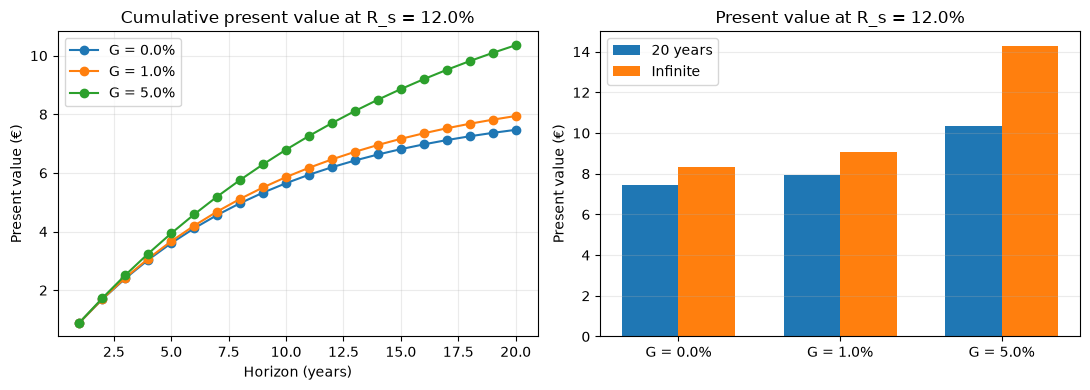

In [2]:
years = list(range(1, N_YEARS + 1))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Cumulative present value through each year
for G in GROWTH_RATES:
    cumulative_values = []
    running_value = 0.0
    for year in years:
        running_value += cash_flow(year, G) / (1 + R_S) ** year
        cumulative_values.append(running_value)
    axes[0].plot(years, cumulative_values, marker="o", label=f"G = {G:.1%}")
axes[0].set(
    title=f"Cumulative present value at R_s = {R_S:.1%}",
    xlabel="Horizon (years)",
    ylabel="Present value (€)",
)
axes[0].legend()
axes[0].grid(alpha=0.25)

# Finite and infinite values
x = list(range(len(GROWTH_RATES)))
width = 0.35
finite_values = [finite_value(R_S, G) for G in GROWTH_RATES]
infinite_values = [infinite_value(R_S, G) for G in GROWTH_RATES]
axes[1].bar([value - width / 2 for value in x], finite_values, width, label="20 years")
axes[1].bar([value + width / 2 for value in x], infinite_values, width, label="Infinite")
axes[1].set(
    title=f"Present value at R_s = {R_S:.1%}",
    ylabel="Present value (€)",
    xticks=x,
    xticklabels=[f"G = {G:.1%}" for G in GROWTH_RATES],
)
axes[1].legend()
axes[1].grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()

## References

[1] J. Dahlquist and R. Knight, *Principles of Finance*. OpenStax, 2022. [Section 7.2, Time Value of Money Basics](https://openstax.org/books/principles-finance-2e/pages/7-2-time-value-of-money-tvm-basics); [Section 8.1, Perpetuities](https://openstax.org/books/principles-finance-2e/pages/8-1-perpetuities); [Section 8.2, Annuities](https://openstax.org/books/principles-finance-2e/pages/8-2-annuities).